In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
!pip install lime
import lime
from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OrdinalEncoder

from xgboost import XGBRegressor

np.random.seed(42)
shap.initjs()



### Dataset Description

The dataset consists of fitness and workout-related records used to predict **Calories_Burned**. Each row represents a single workout or individual observation and includes a mix of physiological measures (e.g., average heart rate), body characteristics (e.g., BMI), and behavioral variables (e.g., workout frequency). The target variable is continuous, and the feature set contains both numerical and categorical attributes.


In [ ]:
#  Data Loading & Inspection

df = pd.read_csv("Final_data.csv")

TARGET_COL = "Calories_Burned"
df = df.dropna(subset=[TARGET_COL])

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Numeric features:", numeric_cols[:10])
print("Categorical features:", categorical_cols[:10])
df.head()

Numeric features: ['Age', 'Weight (kg)', 'Height (m)', 'Max_BPM', 'Avg_BPM', 'Resting_BPM', 'Session_Duration (hours)', 'Fat_Percentage', 'Water_Intake (liters)', 'Workout_Frequency (days/week)']
Categorical features: ['Gender', 'Workout_Type', 'meal_name', 'meal_type', 'diet_type', 'cooking_method', 'Name of Exercise', 'Benefit', 'Target Muscle Group', 'Equipment Needed']


,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,...,cal_from_macros,pct_carbs,protein_per_kg,pct_HRR,pct_maxHR,cal_balance,lean_mass_kg,expected_burn,Burns Calories (per 30 min)_bc,Burns_Calories_Bin
0,34.91,Male,65.27,1.62,188.58,157.65,69.05,1.00,1080.90,Strength,...,2139.59,0.500432,1.624789,0.741237,0.835985,725.10,47.777394,685.1600,7.260425e+19,Medium
1,23.37,Female,56.41,1.55,179.43,131.75,73.18,1.37,1809.91,HIIT,...,1711.65,0.500850,1.514093,0.551247,0.734270,-232.91,40.809803,978.6184,1.020506e+20,High
2,33.20,Female,58.98,1.67,175.04,123.95,54.96,0.91,802.26,Cardio,...,1965.92,0.500610,1.663445,0.574534,0.708124,805.74,44.635580,654.5266,1.079607e+20,High
3,38.69,Female,93.78,1.70,191.21,155.10,50.07,1.10,1450.79,HIIT,...,1627.28,0.499533,0.862017,0.744155,0.811150,1206.21,63.007432,773.6300,8.987921e+19,High
4,45.09,Male,52.42,1.88,193.58,152.88,70.84,1.08,1166.40,Strength,...,2659.23,0.500581,2.538153,0.668405,0.789751,303.60,43.347504,711.4176,5.264685e+19,Low


In [ ]:
df.info()
df.describe(include='all').T.head(30)
df.isna().sum().head(30)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 54 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             20000 non-null  float64
 1   Gender                          20000 non-null  object 
 2   Weight (kg)                     20000 non-null  float64
 3   Height (m)                      20000 non-null  float64
 4   Max_BPM                         20000 non-null  float64
 5   Avg_BPM                         20000 non-null  float64
 6   Resting_BPM                     20000 non-null  float64
 7   Session_Duration (hours)        20000 non-null  float64
 8   Calories_Burned                 20000 non-null  float64
 9   Workout_Type                    20000 non-null  object 
 10  Fat_Percentage                  20000 non-null  float64
 11  Water_Intake (liters)           20000 non-null  float64
 12  Workout_Frequency (days/week)   

,0
Age,0
Gender,0
Weight (kg),0
Height (m),0
Max_BPM,0
Avg_BPM,0
Resting_BPM,0
Session_Duration (hours),0
Calories_Burned,0
Workout_Type,0


In [ ]:
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

numeric_cols, categorical_cols[:10]

(['Age',
  'Weight (kg)',
  'Height (m)',
  'Max_BPM',
  'Avg_BPM',
  'Resting_BPM',
  'Session_Duration (hours)',
  'Fat_Percentage',
  'Water_Intake (liters)',
  'Workout_Frequency (days/week)',
  'Experience_Level',
  'BMI',
  'Daily meals frequency',
  'Physical exercise',
  'Carbs',
  'Proteins',
  'Fats',
  'Calories',
  'sugar_g',
  'sodium_mg',
  'cholesterol_mg',
  'serving_size_g',
  'prep_time_min',
  'cook_time_min',
  'rating',
  'Sets',
  'Reps',
  'Burns Calories (per 30 min)',
  'BMI_calc',
  'cal_from_macros',
  'pct_carbs',
  'protein_per_kg',
  'pct_HRR',
  'pct_maxHR',
  'cal_balance',
  'lean_mass_kg',
  'expected_burn',
  'Burns Calories (per 30 min)_bc'],
 ['Gender',
  'Workout_Type',
  'meal_name',
  'meal_type',
  'diet_type',
  'cooking_method',
  'Name of Exercise',
  'Benefit',
  'Target Muscle Group',
  'Equipment Needed'])

In [ ]:
#  Train / Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
#  Preprocessing Pipeline

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

### XGBoost Model Description and Motivation

XGBoost (Extreme Gradient Boosting) is a tree-based ensemble learning algorithm that builds an additive model of decision trees using gradient boosting. Each new tree is trained to correct the residual errors of the previous trees, allowing the model to capture complex nonlinear relationships and feature interactions.

XGBoost was chosen as a model because it delivers strong predictive performance on structured tabular data, handles mixed feature types effectively after preprocessing, and includes built-in regularization mechanisms that reduce overfitting. In addition, its compatibility with advanced explainability techniques (such as SHAP) makes it well-suited for both accurate prediction and transparent model interpretation.


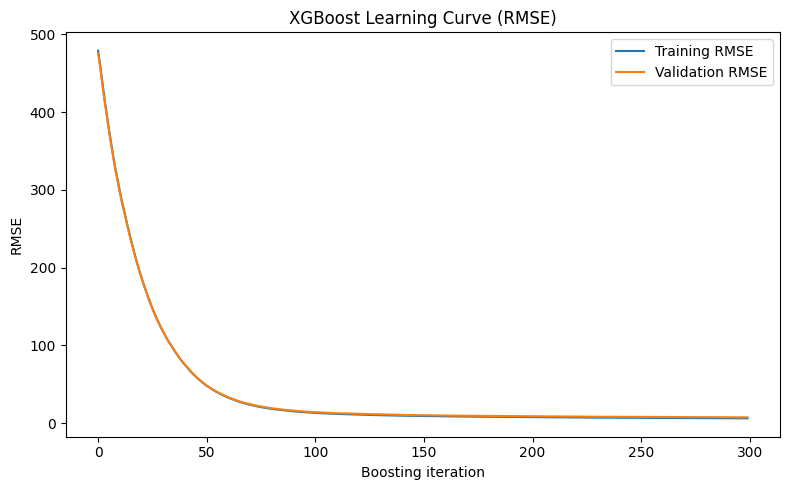

XGBoost Performance
RMSE: 7.606807086931891
R²: 0.9997679732502557


In [ ]:
#  PRIMARY MODEL: XGBoost Regressor
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="rmse"   # <-- set here
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", xgb_model),
    ]
)

# Fit pipeline once (keeps your original flow)
xgb_pipeline.fit(X_train, y_train)

# Build learning curve using the already-fitted preprocessor
preprocessor = xgb_pipeline.named_steps["preprocess"]
model = xgb_pipeline.named_steps["model"]

X_train_trans = preprocessor.transform(X_train)
X_test_trans  = preprocessor.transform(X_test)

# Refit model to record eval history (no eval_metric kwarg here)
model.fit(
    X_train_trans, y_train,
    eval_set=[(X_train_trans, y_train), (X_test_trans, y_test)],
    verbose=False
)

# Extract and plot curve
evals_result = model.evals_result()
train_rmse = evals_result["validation_0"]["rmse"]
val_rmse   = evals_result["validation_1"]["rmse"]

plt.figure(figsize=(8, 5))
plt.plot(train_rmse, label="Training RMSE")
plt.plot(val_rmse, label="Validation RMSE")
plt.xlabel("Boosting iteration")
plt.ylabel("RMSE")
plt.title("XGBoost Learning Curve (RMSE)")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate (same as before)
y_pred = xgb_pipeline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("XGBoost Performance")
print("RMSE:", rmse)
print("R²:", r2)

### Learning Curve Interpretation

The training and validation RMSE decrease rapidly in the early boosting iterations and converge smoothly after approximately 80–100 trees. The near overlap of both curves indicates strong generalization performance and no clear signs of overfitting. The low final RMSE and very high R² value suggest that the model captures the relationship between the input features and calories burned effectively.


### Explainability Methods and Workflow

**Explainability Methods**

- **SHAP (SHapley Additive exPlanations)**  
  Decomposes model predictions into additive feature contributions, enabling both global feature importance analysis and local explanations for individual predictions.


- **Partial Dependence Plots (PDP)**  
  Visualize the average relationship between a feature and the model prediction by marginalizing over other features, revealing nonlinearities and threshold effects.

- **LIME (Local Interpretable Model-agnostic Explanations)**  
  Provides local explanations by approximating the model’s behavior around a single instance with a simple interpretable model.

- **Surrogate Decision Tree**  
  Uses a shallow decision tree trained on the black-box model’s predictions to create a global, rule-based approximation of the model’s decision structure.

**Explainability Workflow**

1. **Global Importance Analysis**  
   Apply SHAP summary plots and permutation importance to identify the most influential features across the entire dataset.

2. **Global Relationship Analysis**  
   Use PDPs on the top-ranked features to understand how changes in these features affect predictions on average.

3. **Global Structural Understanding**  
   Train a surrogate decision tree to obtain a compact, human-readable summary of the model’s overall decision logic, validating its fidelity to the original model.

4. **Local Explanation Analysis**  
   For individual observations, use SHAP or LIME to explain why the model produced a specific prediction.

/tmp/ipython-input-3844919230.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_shap, feature_names=feature_names)


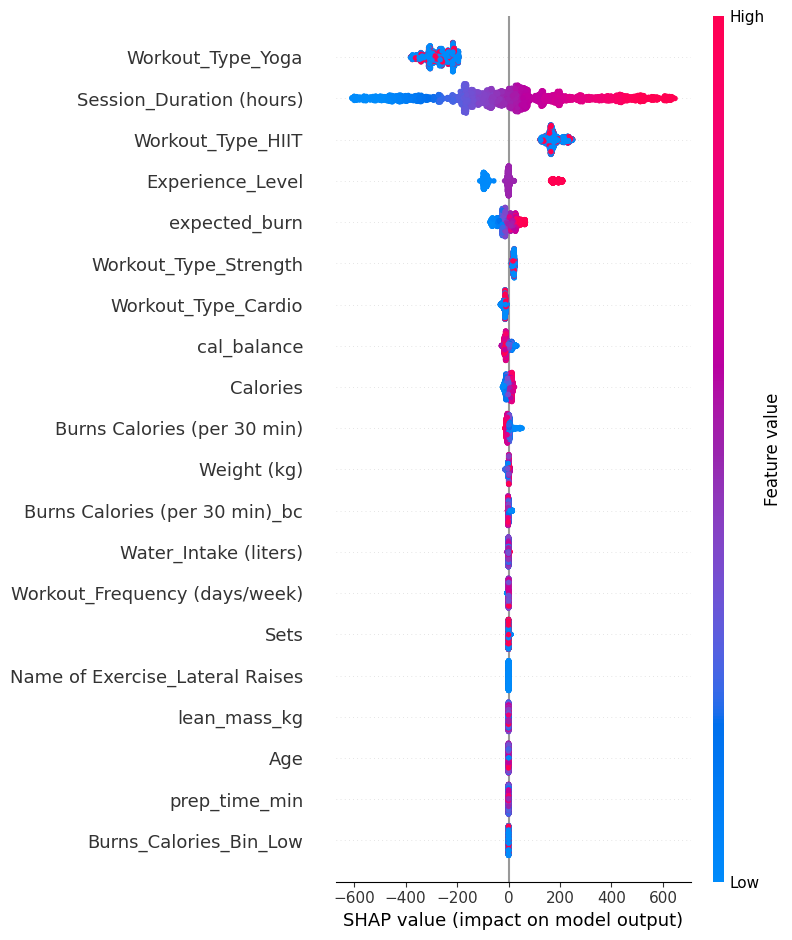

/tmp/ipython-input-3844919230.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_shap, feature_names=feature_names, plot_type="bar")


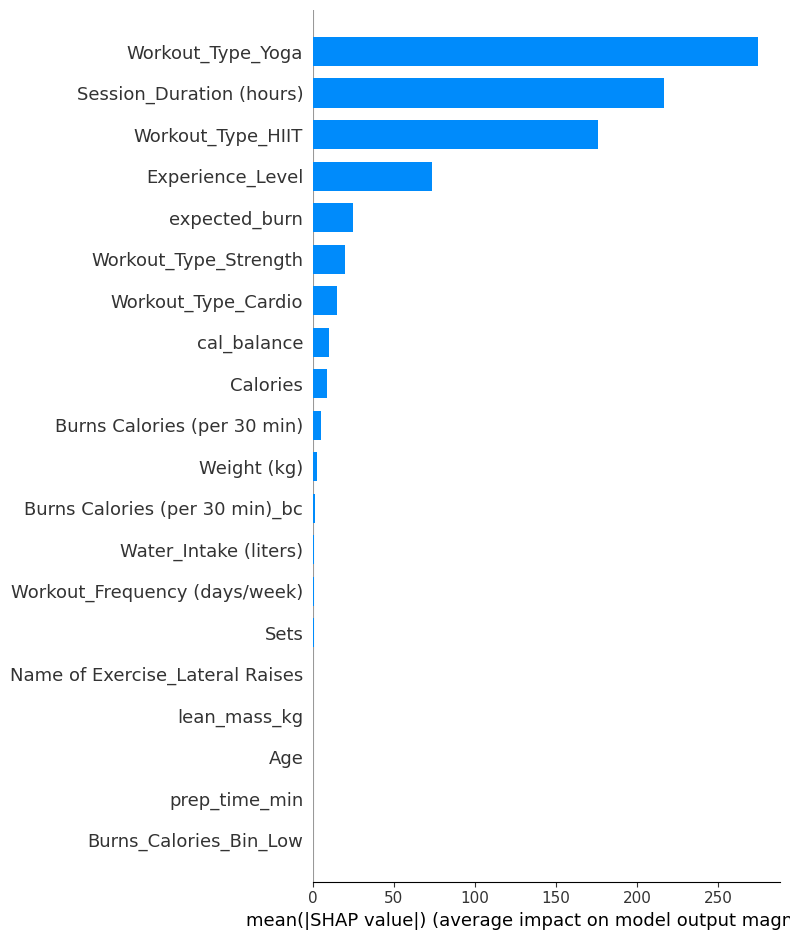

In [ ]:
#  SHAP – Global & Local Explanations (XGBoost)
X_train_trans = preprocess.fit_transform(X_train)
X_test_trans = preprocess.transform(X_test)

if hasattr(X_test_trans, "toarray"):
    X_test_dense = X_test_trans.toarray()
else:
    X_test_dense = X_test_trans

# Feature names (numeric + one-hot)
feature_names = (
    list(numeric_cols)
    + preprocess.named_transformers_["cat"]
      .get_feature_names_out(categorical_cols)
      .tolist()
)

X_test_shap = pd.DataFrame(X_test_dense, columns=feature_names)


explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_shap)

# Colored beeswarm (this should show color now)
shap.summary_plot(shap_values, X_test_shap, feature_names=feature_names)

# Bar plot
shap.summary_plot(shap_values, X_test_shap, feature_names=feature_names, plot_type="bar")


Session_Duration (hours): 0.6887602749527751
Workout_Type: 0.5953636567610594
Experience_Level: 0.074446147082977
expected_burn: 0.01217041648119067
cal_balance: 0.005352412024616238
Calories: 0.0010146082829224135
Burns Calories (per 30 min): 0.0004856760178131858
Weight (kg): 0.0002916007322163128
Burns Calories (per 30 min)_bc: 3.870658920723802e-05
Water_Intake (liters): 2.9572133395872057e-05
Workout_Frequency (days/week): 5.419295241726463e-06
lean_mass_kg: 4.45146531243834e-06
Age: 3.679982238857793e-06
Sets: 3.1596114535403784e-06
Max_BPM: 2.727708794403316e-06


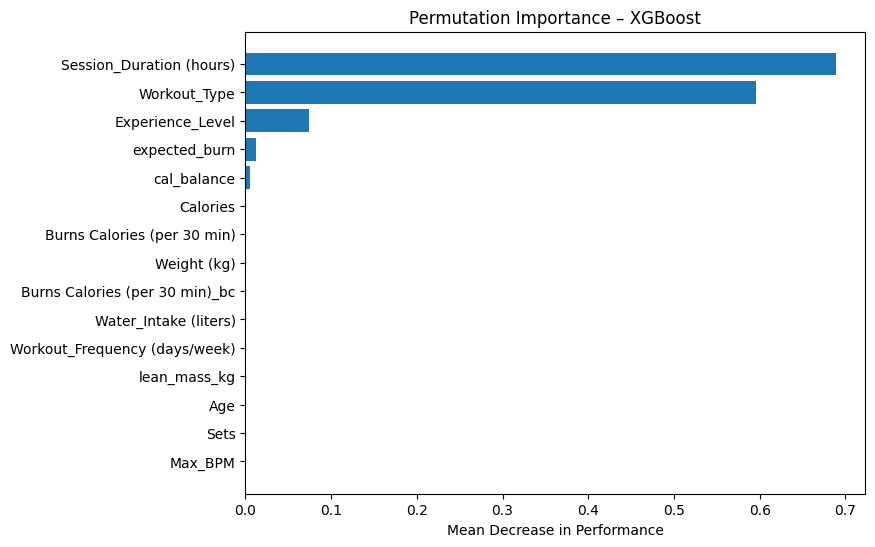


INTERPRETATION (Permutation Importance):
Permutation importance confirms SHAP results. Shuffling high-ranked features causes a strong performance drop, indicating genuine model reliance rather than spurious correlation.


In [ ]:
#  Permutation Importance (XGBoost)


perm = permutation_importance(
    xgb_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

importances = perm.importances_mean
indices = np.argsort(perm.importances_mean)[::-1][:15]

top_n = 15
for i in range(top_n):
    print(f"{X.columns[indices[i]]}: {importances[indices[i]]}")

plt.figure(figsize=(8, 6))
plt.barh(
    range(len(indices)),
    perm.importances_mean[indices][::-1],
)
plt.yticks(range(len(indices)), X.columns[indices][::-1])
plt.xlabel("Mean Decrease in Performance")
plt.title("Permutation Importance – XGBoost")
plt.show()

print("\nINTERPRETATION (Permutation Importance):")
print(
    "Permutation importance confirms SHAP results. "
    "Shuffling high-ranked features causes a strong performance drop, "
    "indicating genuine model reliance rather than spurious correlation."
)

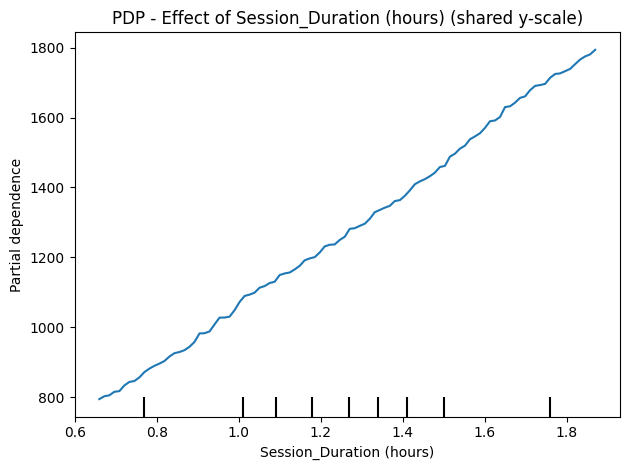

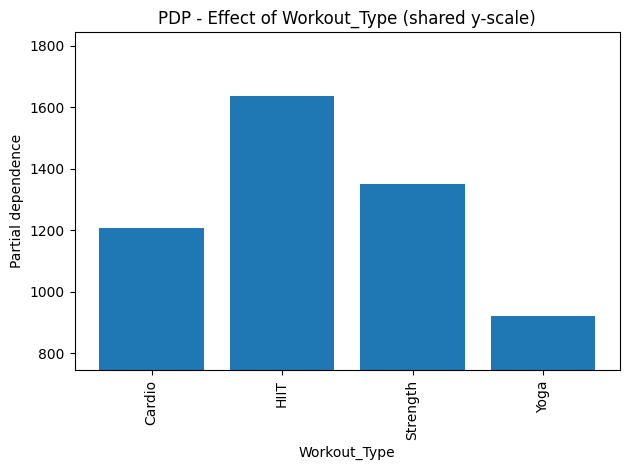

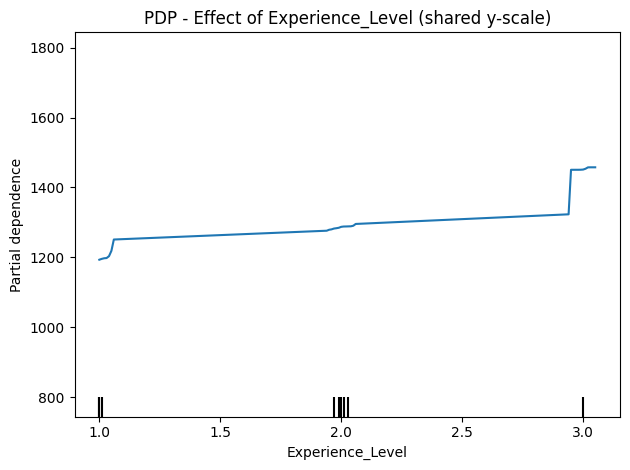


INTERPRETATION (PDP):
PDPs show marginal effects of individual features. Using a shared y-axis makes the relative magnitude of feature effects directly comparable across plots.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

pdp_features = ["Session_Duration (hours)", "Workout_Type", "Experience_Level"]

# --- 1) Compute global y-limits across all PDPs ---
ymins, ymaxs = [], []

tmp_displays = []
for feat in pdp_features:
    is_categorical = feat in categorical_cols

    disp = PartialDependenceDisplay.from_estimator(
        xgb_pipeline,
        X,
        [feat],
        categorical_features=[feat] if is_categorical else None
    )
    tmp_displays.append((feat, disp))

    # Extract plotted y-data from the created axes
    ax = disp.axes_.ravel()[0]
    for line in ax.lines:
        y = line.get_ydata()
        if y is not None and len(y) > 0:
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    plt.close(disp.figure_)  # close temporary figure to avoid duplicates

global_ymin = float(np.min(ymins))
global_ymax = float(np.max(ymaxs))

# Add a small margin for readability
pad = 0.05 * (global_ymax - global_ymin) if global_ymax > global_ymin else 1.0
global_ymin -= pad
global_ymax += pad

# --- 2) Re-plot PDPs with the same y-scale ---
for feat in pdp_features:
    is_categorical = feat in categorical_cols

    disp = PartialDependenceDisplay.from_estimator(
        xgb_pipeline,
        X,
        [feat],
        categorical_features=[feat] if is_categorical else None
    )

    ax = disp.axes_.ravel()[0]
    ax.set_ylim(global_ymin, global_ymax)
    ax.set_title(f"PDP - Effect of {feat} (shared y-scale)")
    plt.tight_layout()
    plt.show()

print("\nINTERPRETATION (PDP):")
print(
    "PDPs show marginal effects of individual features. Using a shared y-axis "
    "makes the relative magnitude of feature effects directly comparable across plots."
)


In [ ]:
#Lime
target_col = "Calories_Burned"
X_lime = df.drop(columns=[target_col]).copy()
y_lime = df[target_col].copy()

# Ensure categorical_cols is up-to-date for X_lime
numeric_cols = X_lime.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_lime.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

# --- 1) Ordinal-encode categorical features for LIME sampling ---
lime_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_lime_enc = X_lime.copy()
if len(categorical_cols) > 0:
    X_lime_enc[categorical_cols] = lime_encoder.fit_transform(X_lime_enc[categorical_cols])

# --- 2) Train/test split for LIME explainer (independent from model split is OK) ---
X_train_lime, X_test_lime, y_train_lime, y_test_lime = train_test_split(
    X_lime_enc, y_lime, test_size=0.2, random_state=42
)

# --- 3) Prediction wrapper: convert ordinal codes back to original categories ---
def lime_predict_pipeline(x_numpy):
    """
    x_numpy: numpy array from LIME (same column order as X_lime_enc)
    returns: predictions from the already-trained xgb_pipeline
    """
    x_df = pd.DataFrame(x_numpy, columns=X_lime_enc.columns)

    # Convert ordinal codes back to original categories so the pipeline can one-hot encode
    if len(categorical_cols) > 0:
        x_df[categorical_cols] = lime_encoder.inverse_transform(x_df[categorical_cols])

        # Ensure dtype is object for categorical columns (helps OneHotEncoder robustness)
        for c in categorical_cols:
            x_df[c] = x_df[c].astype("object")

    return xgb_pipeline.predict(x_df)

# --- 4) Build LIME explainer ---
lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.values,
    feature_names=X_lime_enc.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

# --- 5) Explain one instance ---
i = 0
instance = X_test_lime.iloc[i].values

lime_exp = lime_explainer.explain_instance(
    data_row=instance,
    predict_fn=lime_predict_pipeline,
    num_features=10
)

# --- 6) Render in notebook (with safe fallbacks) ---
try:
    lime_exp.show_in_notebook(show_table=True)
except Exception:
    try:
        from IPython.display import HTML, display
        display(HTML(lime_exp.as_html(show_table=True)))
    except Exception:
        print("Could not render LIME HTML. Falling back to text output:\n")
        for feature, weight in lime_exp.as_list():
            print(f"{feature}: {weight:.4f}")

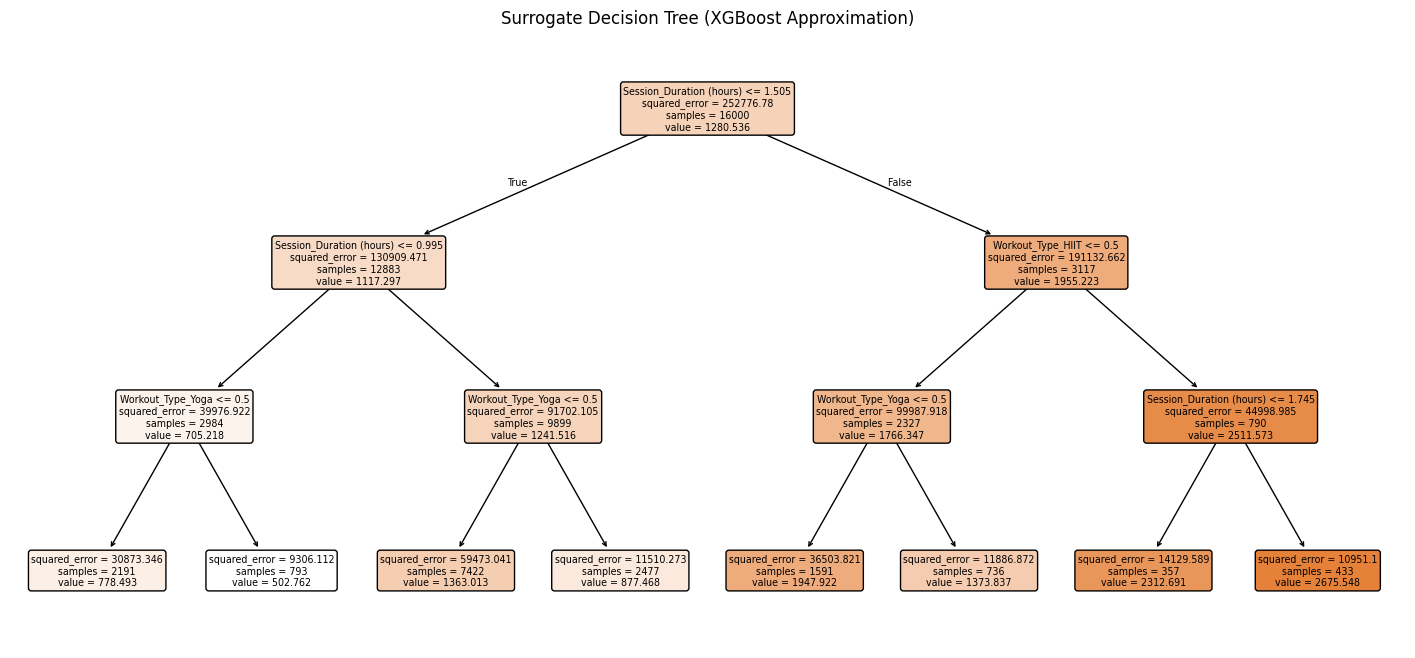


INTERPRETATION (Surrogate Model):
The surrogate tree approximates XGBoost behavior using a shallow structure. It reveals dominant split logic and provides a simplified global explanation of an otherwise complex ensemble.


In [ ]:
#  Surrogate Decision Tree (Global Approximation)


y_train_pred = xgb_pipeline.predict(X_train)

surrogate_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
surrogate_tree.fit(X_train_trans, y_train_pred)

plt.figure(figsize=(18, 8))
plot_tree(
    surrogate_tree,
    feature_names=feature_names,
    filled=True,
    rounded=True,
)
plt.title("Surrogate Decision Tree (XGBoost Approximation)")
plt.show()

print("\nINTERPRETATION (Surrogate Model):")
print(
    "The surrogate tree approximates XGBoost behavior using a shallow structure. "
    "It reveals dominant split logic and provides a simplified global explanation "
    "of an otherwise complex ensemble."
)

### Random Forest Model Description and Motivation

Random Forest is an ensemble learning method that combines the predictions of many decision trees trained on different bootstrap samples of the data, using random subsets of features at each split. By averaging across trees, Random Forest reduces variance and improves robustness compared to a single decision tree.

Random Forest was chosen as a comparison model because it performs strongly on structured tabular data, captures nonlinear relationships and feature interactions without extensive tuning, and provides a stable baseline against which the XGBoost model can be evaluated. Its ensemble structure also supports multiple explainability techniques, making it suitable for both performance comparison and interpretability analysis.


In [ ]:
#MODEL: Random Forest


rf_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1
        )),
    ]
)

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, rf_pred))
r2_rf = r2_score(y_test, rf_pred)

print("\nRandom Forest Performance")
print("RMSE:", rmse_rf)
print("R²:", r2_rf)


Random Forest Performance
RMSE: 2.69459693981791
R²: 0.9999708847263707


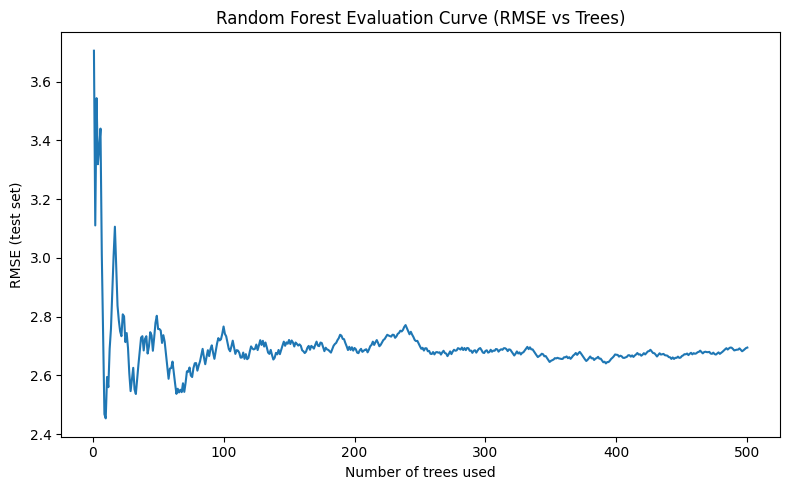

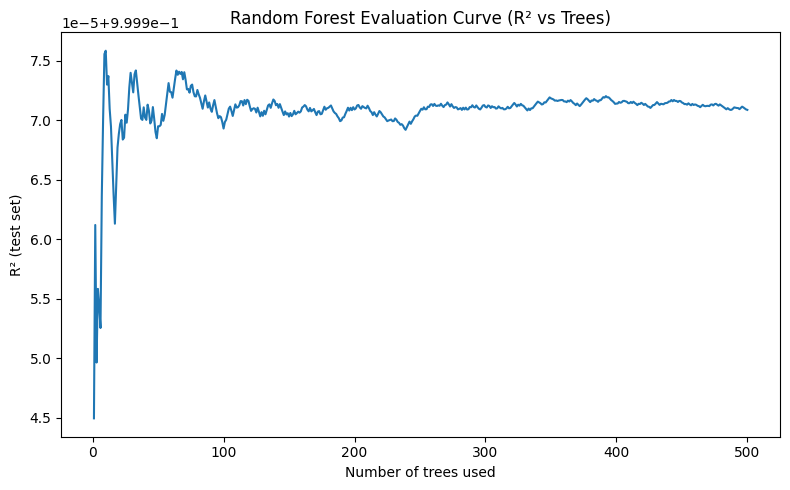

In [ ]:
import joblib

# Load the saved pipeline
rf_pipeline = joblib.load("rf_pipeline.joblib")

# Access fitted parts
preprocessor = rf_pipeline.named_steps["preprocess"]
rf_model = rf_pipeline.named_steps["model"]

# Transform test data once (no training)
X_test_trans = preprocessor.transform(X_test)

# Build evaluation curve: RMSE/R² vs number of trees used
estimators = rf_model.estimators_
n_trees = len(estimators)

rmse_curve = np.empty(n_trees)
r2_curve = np.empty(n_trees)

running_pred = np.zeros(X_test_trans.shape[0], dtype=float)

for i, tree in enumerate(estimators, start=1):
    running_pred += tree.predict(X_test_trans)
    y_pred_i = running_pred / i

    rmse_curve[i-1] = np.sqrt(mean_squared_error(y_test, y_pred_i))
    r2_curve[i-1] = r2_score(y_test, y_pred_i)

# Plot RMSE curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_trees + 1), rmse_curve)
plt.xlabel("Number of trees used")
plt.ylabel("RMSE (test set)")
plt.title("Random Forest Evaluation Curve (RMSE vs Trees)")
plt.tight_layout()
plt.show()

# Plot R² curve (optional)
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_trees + 1), r2_curve)
plt.xlabel("Number of trees used")
plt.ylabel("R² (test set)")
plt.title("Random Forest Evaluation Curve (R² vs Trees)")
plt.tight_layout()
plt.show()


### Explainability Methods for Random Forest

The same explainability techniques used for the XGBoost model are applied to the Random Forest model. These include SHAP for global and local feature contributions, permutation importance for assessing performance-based feature relevance, partial dependence plots for analyzing average feature–response relationships, LIME for local instance-level explanations, and a surrogate decision tree for summarizing the model’s global decision logic. This consistent setup enables a direct and fair interpretability comparison between Random Forest and XGBoost.


/tmp/ipython-input-2627142299.py:14: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(rf_shap_values, X_test_trans_dense, feature_names=feature_names)


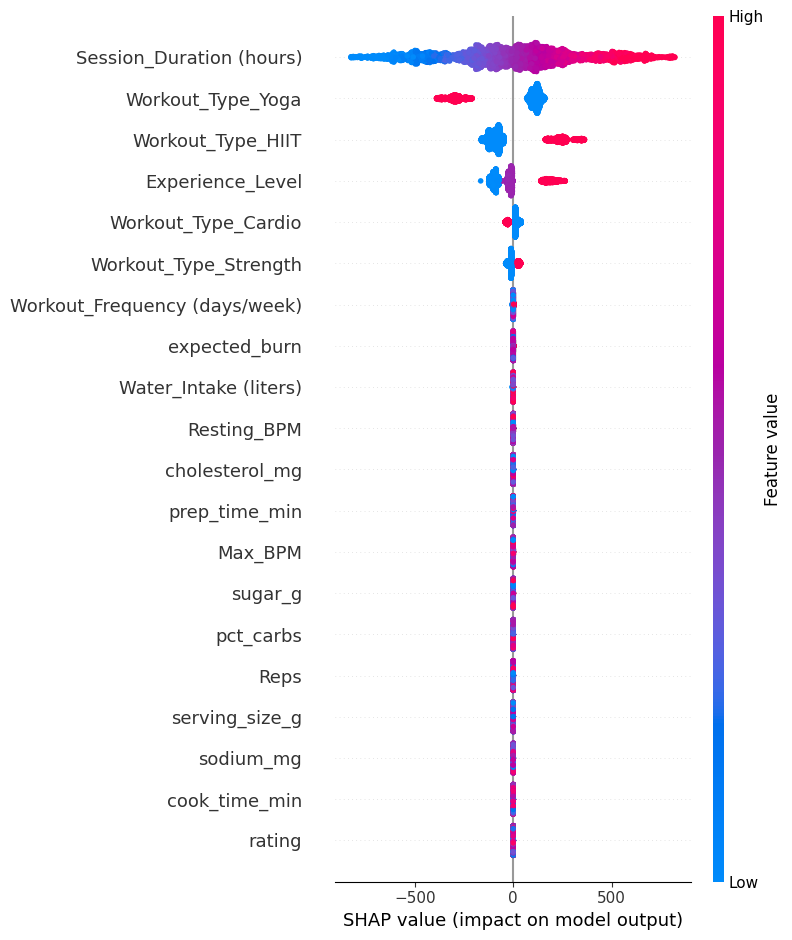

/tmp/ipython-input-2627142299.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(rf_shap_values, X_test_trans_dense, feature_names=feature_names, plot_type='bar', show=True)


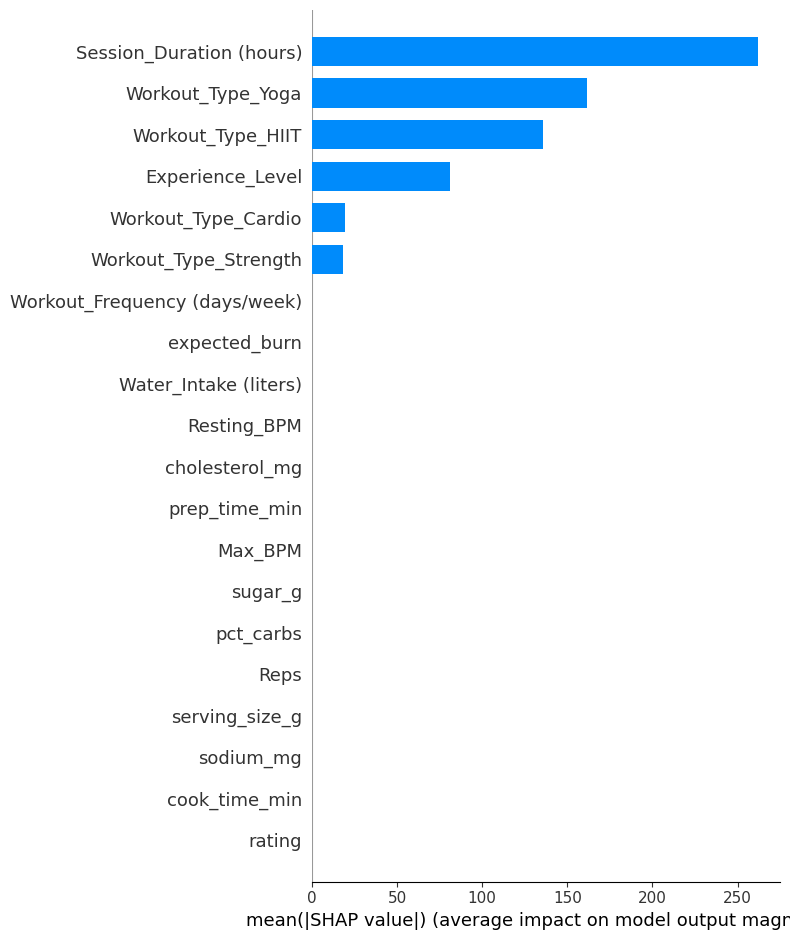

In [ ]:
# SHAP – Random Forest

rf_model = rf_pipeline.named_steps["model"]
rf_explainer = shap.TreeExplainer(rf_model)


if hasattr(X_test_trans, 'toarray'):
    X_test_trans_dense = X_test_trans.toarray().astype(float)
else:
    X_test_trans_dense = X_test_trans.astype(float)

rf_shap_values = rf_explainer.shap_values(X_test_trans_dense)

shap.summary_plot(rf_shap_values, X_test_trans_dense, feature_names=feature_names)

shap.summary_plot(rf_shap_values, X_test_trans_dense, feature_names=feature_names, plot_type='bar', show=True)


Top Random Forest permutation importances:
 1. Session_Duration (hours): 0.977136
 2. Workout_Type: 0.658838
 3. Experience_Level: 0.072912
 4. Workout_Frequency (days/week): 0.000038
 5. Water_Intake (liters): 0.000006
 6. expected_burn: 0.000001
 7. Name of Exercise: 0.000000
 8. Gender: 0.000000
 9. Type of Muscle: 0.000000
10. Max_BPM: 0.000000
11. Calories: 0.000000
12. Difficulty Level: 0.000000
13. serving_size_g: 0.000000
14. Target Muscle Group: 0.000000
15. BMI: 0.000000


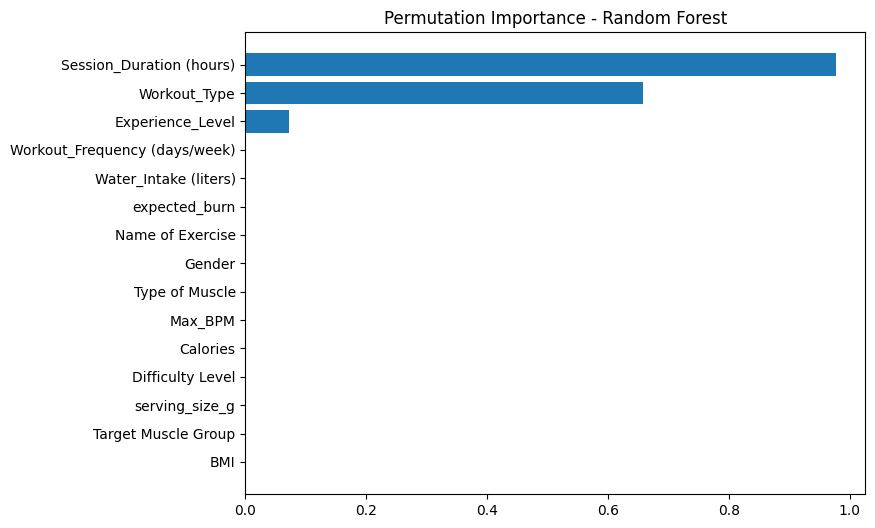

In [ ]:
#  RANDOM FOREST – PERMUTATION IMPORTANCE


perm_rf = permutation_importance(
    rf_pipeline, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

perm_importances_rf = perm_rf.importances_mean
idx_rf = np.argsort(perm_importances_rf )[::-1][:15]

top_n = 15
print("Top Random Forest permutation importances:")
for i in range(top_n):
    print(f"{i+1:2d}. {X.columns[idx_rf[i]]}: {perm_importances_rf[idx_rf[i]]:.6f}")

plt.figure(figsize=(8, 6))
plt.barh(range(len(idx_rf)), perm_rf.importances_mean[idx_rf][::-1])
plt.yticks(range(len(idx_rf)), X.columns[idx_rf][::-1])
plt.title("Permutation Importance - Random Forest")
plt.show()

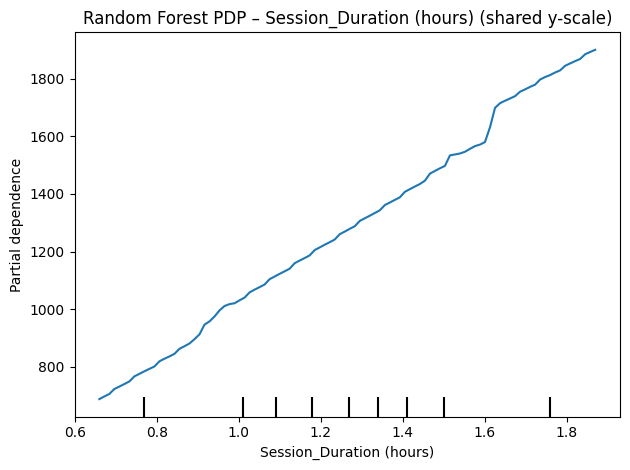

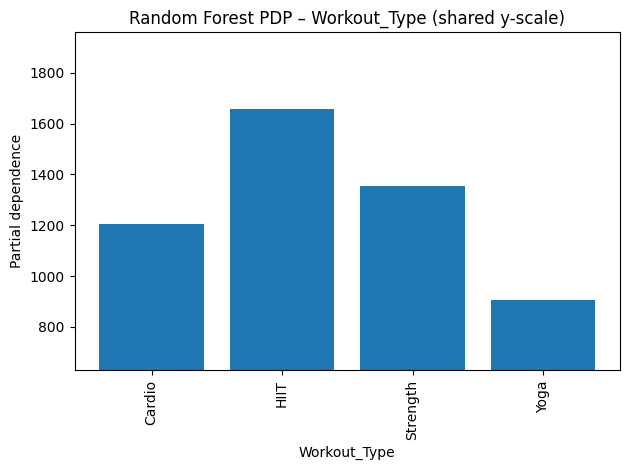

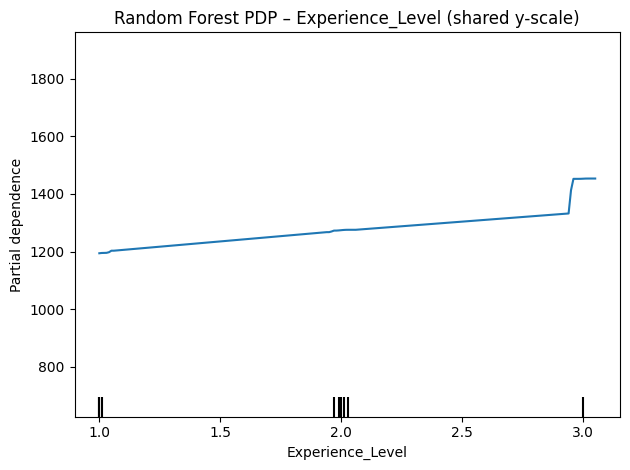

In [ ]:
pdp_features = ["Session_Duration (hours)", "Workout_Type", "Experience_Level"]

# --- 1) Compute global y-limits across PDPs ---
ymins, ymaxs = [], []

for f in pdp_features:
    is_categorical = f in categorical_cols

    disp = PartialDependenceDisplay.from_estimator(
        rf_pipeline,
        X,
        [f],
        categorical_features=[f] if is_categorical else None
    )

    ax = disp.axes_.ravel()[0]
    for line in ax.lines:
        y = line.get_ydata()
        if y is not None and len(y) > 0:
            ymins.append(np.nanmin(y))
            ymaxs.append(np.nanmax(y))

    plt.close(disp.figure_)  # avoid duplicate plots

global_ymin = float(np.min(ymins))
global_ymax = float(np.max(ymaxs))

pad = 0.05 * (global_ymax - global_ymin) if global_ymax > global_ymin else 1.0
global_ymin -= pad
global_ymax += pad

# --- 2) Plot PDPs again with shared y-scale ---
for f in pdp_features:
    is_categorical = f in categorical_cols

    disp = PartialDependenceDisplay.from_estimator(
        rf_pipeline,
        X,
        [f],
        categorical_features=[f] if is_categorical else None
    )

    ax = disp.axes_.ravel()[0]
    ax.set_ylim(global_ymin, global_ymax)
    ax.set_title(f"Random Forest PDP – {f} (shared y-scale)")
    plt.tight_layout()
    plt.show()

In [ ]:
#  RANDOM FOREST – LIME
if "df" in globals() and "target_col" in globals():
    y_rf_lime = df[target_col].copy()
else:
    y_rf_lime = y  # fallback if you don't have df/target_col in scope

# Ordinal-encode categoricals for LIME sampling
lime_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_lime_rf = X.copy()
if len(categorical_cols) > 0:
    X_lime_rf[categorical_cols] = lime_encoder.fit_transform(X_lime_rf[categorical_cols])

# Split for LIME explainer
X_train_lime_rf, X_test_lime_rf, y_train_lime_rf, y_test_lime_rf = train_test_split(
    X_lime_rf, y_rf_lime, test_size=0.2, random_state=42
)

def rf_predict_wrapper(x_numpy):
    """
    x_numpy: numeric array from LIME (ordinal-encoded categoricals)
    """
    x_df = pd.DataFrame(x_numpy, columns=X.columns)

    # Convert ordinal codes back to original categories so the real pipeline can one-hot encode
    if len(categorical_cols) > 0:
        x_df[categorical_cols] = lime_encoder.inverse_transform(x_df[categorical_cols])
        for c in categorical_cols:
            x_df[c] = x_df[c].astype("object")

    return rf_pipeline.predict(x_df)

# Create LIME explainer (FIXED line)
lime_rf = LimeTabularExplainer(
    training_data=X_train_lime_rf.values,
    feature_names=X.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

# Explain one instance
i = 0
instance_rf = X_test_lime_rf.iloc[i].values

exp_rf = lime_rf.explain_instance(
    data_row=instance_rf,
    predict_fn=rf_predict_wrapper,
    num_features=10
)

# Render
try:
    exp_rf.show_in_notebook(show_table=True)
except Exception:
    try:
        from IPython.display import HTML, display
        display(HTML(exp_rf.as_html(show_table=True)))
    except Exception:
        print("Could not render LIME HTML in this environment. Falling back to text output.")
        for feature, weight in exp_rf.as_list():
            print(f"{feature}: {weight:.4f}")

print("\nINTERPRETATION (Random Forest – LIME):")
print(
    "The local explanation highlights which features push the Random Forest prediction "
    "up or down for this specific instance. Contributions are often more balanced due "
    "to averaging across many trees."
)


INTERPRETATION (Random Forest – LIME):
The local explanation highlights which features push the Random Forest prediction up or down for this specific instance. Contributions are often more balanced due to averaging across many trees.


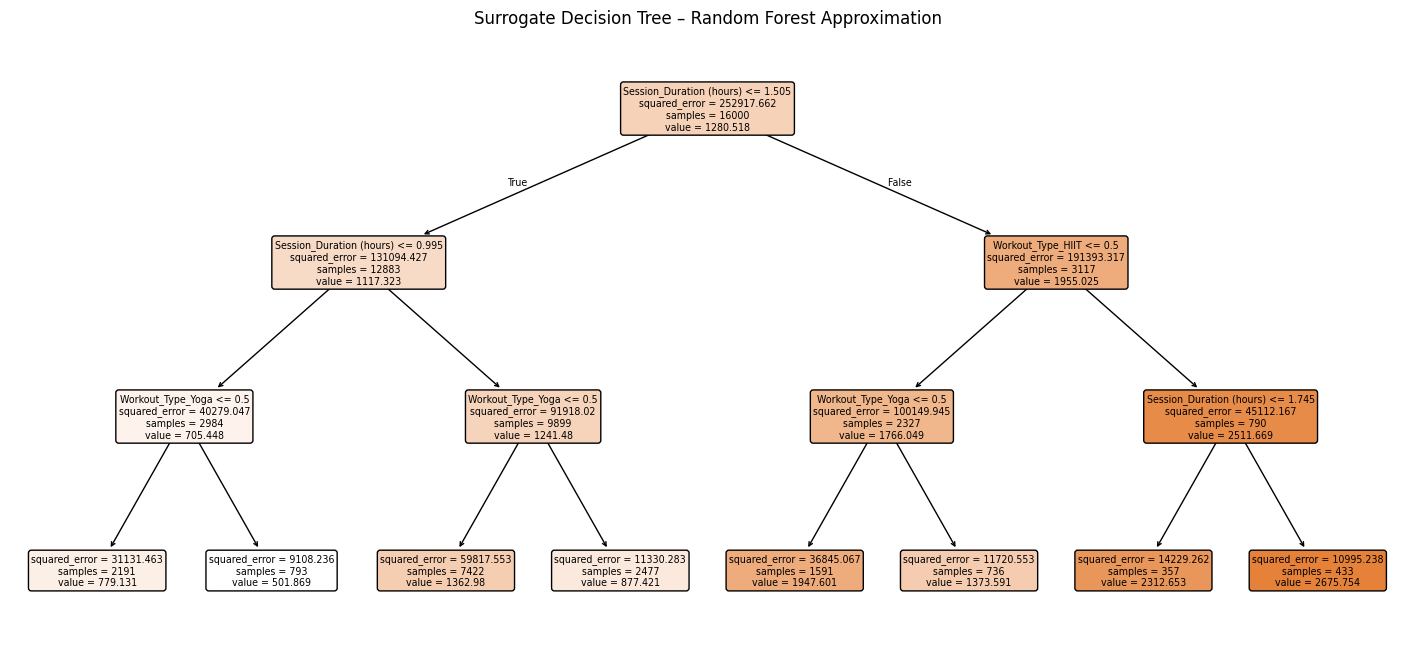

In [ ]:

# RANDOM FOREST – Surrogate Decision Tree

y_train_pred_rf = rf_pipeline.predict(X_train)


preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)
X_train_trans = preprocess.fit_transform(X_train)
feature_names = (
    numeric_cols
    + preprocess.named_transformers_["cat"]
    .get_feature_names_out(categorical_cols)
    .tolist()
)


rf_surrogate_tree = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

rf_surrogate_tree.fit(X_train_trans, y_train_pred_rf)

plt.figure(figsize=(18, 8))
plot_tree(
    rf_surrogate_tree,
    feature_names=feature_names,
    filled=True,
    rounded=True
)
plt.title("Surrogate Decision Tree – Random Forest Approximation")
plt.show()


